<a href="https://colab.research.google.com/github/Wahyudi-Satriawan/244107020137_TI3H_PembelajaranMesin/blob/main/Jobsheet%20Dataset%20PBL/JS02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Wahyudi-Satriawan/244107020137_TI3H_PembelajaranMesin/blob/main/Jobsheet%20Dataset%20PBL/JS02.ipynb)

# JOBSHEET 02: PEMAHAMAN DATA (EDA) DAN PRA-PENGOLAHAN DATA
### Eksplorasi, Audit Anomali, dan Pembersihan Empiris pada Dataset Mentah Properti PBL RumahPoint
**Mata Kuliah:** Pembelajaran Mesin — Semester 5 (Tahun Akademik 2025/2026)  
**Mahasiswa:** Wahyudi Satriawan Hamid  
**NIM / Kelas:** 244107020137 / TI-3H  
**Program Studi:** D-IV Teknik Informatika — Jurusan Teknologi Informasi — Politeknik Negeri Malang  

---

## Ringkasan Eksekutif & Peta Adaptasi Modul ke Dataset PBL
Jobsheet ini berfokus pada penguasaan tahapan fundamental rekayasa data machine learning: **Exploratory Data Analysis (EDA)**, deteksi anomali/outlier, penanganan missing values, encoding variabel kategorikal, dan standardisasi fitur numerik.

In [39]:
# ==============================================================================
# PENGATURAN AWAL: IMPORT LIBRARY, SEED REPRODUSIBILITAS, & KONFIGURASI VISUAL
# ==============================================================================
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

# Scikit-Learn Preprocessing & Imputation
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# Kunci random seed untuk reprodusibilitas
np.random.seed(42)

# Konfigurasi visualisasi
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.autolayout'] = True
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

print("=" * 75)
print("SISTEM INFORMASI LINGKUNGAN KOMPUTASI (GOOGLE COLAB / LOCAL JUPYTER)")
print("=" * 75)
print(f"Versi Python       : {sys.version.split()[0]}")
print(f"Versi NumPy        : {np.__version__}")
print(f"Versi Pandas       : {pd.__version__}")
print(f"Versi Scikit-Learn : {sklearn.__version__}")
print("=" * 75)

SISTEM INFORMASI LINGKUNGAN KOMPUTASI (GOOGLE COLAB / LOCAL JUPYTER)
Versi Python       : 3.13.18
Versi NumPy        : 2.4.6
Versi Pandas       : 2.2.3
Versi Scikit-Learn : 1.6.1


## Bagian 1 — Pemuatan Data Mentah & Audit EDA Awal (Adaptasi Praktikum 1)

In [40]:
# ==============================================================================
# LOADER DUAL-MODE: PEMUATAN DATASET MENTAH (PROPERTI_MULTI_KOTA.CSV)
# ==============================================================================
DATASET_FILENAME = "properti_multi_kota.csv"
LOCAL_PATH = os.path.join("..", "Dataset", DATASET_FILENAME)
GITHUB_RAW_URL = f"https://raw.githubusercontent.com/Wahyudi-Satriawan/244107020137_TI3H_PembelajaranMesin/main/Dataset/{DATASET_FILENAME}"

if os.path.exists(LOCAL_PATH):
    print(f"[LOADER] Memuat dataset mentah dari path lokal: {LOCAL_PATH}")
    df_raw = pd.read_csv(LOCAL_PATH)
else:
    print(f"[LOADER] Path lokal tidak ditemukan. Mengunduh dataset mentah dari GitHub RAW: {GITHUB_RAW_URL}")
    df_raw = pd.read_csv(GITHUB_RAW_URL)

print(f"[LOADER] Status: Berhasil memuat {df_raw.shape[0]:,} baris dan {df_raw.shape[1]} kolom.")

[LOADER] Path lokal tidak ditemukan. Mengunduh dataset mentah dari GitHub RAW: https://raw.githubusercontent.com/Wahyudi-Satriawan/244107020137_TI3H_PembelajaranMesin/main/Dataset/properti_multi_kota.csv
[LOADER] Status: Berhasil memuat 64,650 baris dan 8 kolom.


### 1.1 Audit Dimensi, Struktur Kolom, dan Tipe Data
Memeriksa ukuran matriks dataset mentah, nama seluruh variabel, dan tipe representasi data di memori.

In [41]:
print("=" * 60)
print("AUDIT DIMENSI DAN STRUKTUR KOLOM DATASET MENTAH")
print("=" * 60)
print(f"Jumlah Baris : {df_raw.shape[0]:,}")
print(f"Jumlah Kolom : {df_raw.shape[1]}")
print("\nStruktur Kolom dan Tipe Data:")
print(df_raw.dtypes)
print("\nRingkasan Informasi DataFrame (df_raw.info()):")
df_raw.info()
print("\nCuplikan 5 Baris Pertama:")
display(df_raw.head())

AUDIT DIMENSI DAN STRUKTUR KOLOM DATASET MENTAH
Jumlah Baris : 64,650
Jumlah Kolom : 8

Struktur Kolom dan Tipe Data:
sumber                 object
lokasi                 object
luas_m2               float64
luas_bangunan         float64
jumlah_kamar          float64
jumlah_kamar_mandi    float64
usia_bangunan         float64
harga                 float64
dtype: object

Ringkasan Informasi DataFrame (df_raw.info()):
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64650 entries, 0 to 64649
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   sumber              64650 non-null  object 
 1   lokasi              64650 non-null  object 
 2   luas_m2             64650 non-null  float64
 3   luas_bangunan       63046 non-null  float64
 4   jumlah_kamar        64254 non-null  float64
 5   jumlah_kamar_mandi  64242 non-null  float64
 6   usia_bangunan       4789 non-null   float64
 7   harga               64650 

,sumber,lokasi,luas_m2,luas_bangunan,jumlah_kamar,jumlah_kamar_mandi,usia_bangunan,harga
0,uas-properti/Jabodetabek,Tangerang,30.0,NaN,3.0,3.0,33.0,2.037543e+08
1,uas-properti/Jabodetabek,Bekasi,122.0,NaN,5.0,4.0,19.0,1.058032e+09
2,uas-properti/Jabodetabek,Bekasi,142.8,NaN,1.0,1.0,9.0,1.335793e+09
3,uas-properti/Jabodetabek,Bekasi,152.6,NaN,4.0,3.0,6.0,1.613771e+09
4,uas-properti/Jabodetabek,Depok,61.2,NaN,1.0,1.0,9.0,5.221562e+08


### 1.2 Ringkasan Statistik Deskriptif & Deteksi Persentil Ekstrem
Memeriksa sebaran statistik fitur numerik dengan mengevaluasi persentil 1%, 5%, 25%, 50%, 75%, 95%, dan 99% guna mengidentifikasi *heavy right-skewed tail* dan anomali nilai minimum.

In [42]:
percentiles = [0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
desc_stats = df_raw.describe(percentiles=percentiles).T
print("=" * 80)
print("STATISTIK DESKRIPTIF FITUR NUMERIK (DENGAN PERSENTIL EKSTREM P1 - P99)")
print("=" * 80)
display(desc_stats.style.format("{:,.2f}"))

STATISTIK DESKRIPTIF FITUR NUMERIK (DENGAN PERSENTIL EKSTREM P1 - P99)


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
luas_m2,"64,650.00","1,400.53","275,427.05",1.00,36.00,60.00,72.00,98.00,150.00,600.00,"2,000.00","70,000,000.00"
luas_bangunan,"63,046.00","159,119.60","39,336,451.28",0.00,22.00,30.00,40.00,63.00,125.00,400.00,950.00,"9,876,543,000.00"
jumlah_kamar,"64,254.00","6,305.89","1,597,735.69",0.00,0.00,1.00,2.00,2.00,3.00,5.00,10.00,"405,000,000.00"
jumlah_kamar_mandi,"64,242.00","14,540.74","3,684,998.78",0.00,0.00,1.00,1.00,2.00,2.00,4.00,7.00,"934,000,000.00"
usia_bangunan,"4,789.00","1,310.07",950.01,0.00,0.00,5.00,27.00,"2,010.00","2,021.00","2,026.00","2,026.00","2,026.00"
harga,"64,650.00","101,957,087,039,993.50","9,695,373,797,568,978.00",1.00,"107,898,000.00","180,000,000.00","377,000,000.00","739,190,785.50","1,645,000,000.00","5,700,000,000.00","21,000,000,000.00","1,111,111,111,111,111,168.00"


### 1.3 Audit Duplikasi Data dan Kardinalitas Fitur Kategorikal
Mendeteksi keberadaan baris identik (duplikat persis) dan mengevaluasi keragaman kategori pada kolom teks (`lokasi` dan `sumber`).

In [43]:
n_duplicates = df_raw.duplicated().sum()
pct_duplicates = (n_duplicates / len(df_raw)) * 100

print("=" * 60)
print("AUDIT DUPLIKASI DATA MENTAH")
print("=" * 60)
print(f"Jumlah Baris Duplikat Persis : {n_duplicates:,} baris ({pct_duplicates:.2f}%)")
print(f"Jumlah Baris Unik             : {len(df_raw) - n_duplicates:,} baris ({100 - pct_duplicates:.2f}%)")

print("\n" + "=" * 60)
print("AUDIT KARDINALITAS KOLOM KATEGORIKAL")
print("=" * 60)
print(f"Jumlah Nilai Unik Kolom 'lokasi' : {df_raw['lokasi'].nunique():,} kota/kabupaten")
print(f"Jumlah Nilai Unik Kolom 'sumber' : {df_raw['sumber'].nunique():,} sumber portal")
print("\nDistribusi Frekuensi Sumber Data:")
print(df_raw['sumber'].value_counts(dropna=False))

AUDIT DUPLIKASI DATA MENTAH
Jumlah Baris Duplikat Persis : 7,156 baris (11.07%)
Jumlah Baris Unik             : 57,494 baris (88.93%)

AUDIT KARDINALITAS KOLOM KATEGORIKAL
Jumlah Nilai Unik Kolom 'lokasi' : 595 kota/kabupaten
Jumlah Nilai Unik Kolom 'sumber' : 513 sumber portal

Distribusi Frekuensi Sumber Data:
sumber
FLUS/komersil               39423
rumah123/Surabaya            2000
uas-properti/Jabodetabek     1530
99.co/Bekasi                  400
99.co/Tangerang               400
                            ...  
rumah123/Sumba Timur            1
rumah123/Sumbawa                1
rumah123/Way Kanan              1
99.co/Agam                      1
99.co/Aceh Barat                1
Name: count, Length: 513, dtype: int64


### 1.4 Audit Nilai Hilang (*Missing Values*) per Kolom
Mengidentifikasi tingkat kekosongan data per atribut untuk menentukan kelayakan kolom sebagai fitur pemodelan.

In [44]:
missing_count = df_raw.isnull().sum()
missing_pct = (df_raw.isnull().sum() / len(df_raw)) * 100
missing_df = pd.DataFrame({
    'Jumlah_Missing': missing_count,
    'Persentase_Missing (%)': missing_pct,
    'Tipe_Data': df_raw.dtypes
}).sort_values(by='Jumlah_Missing', ascending=False)

print("=" * 70)
print("AUDIT NILAI HILANG (MISSING VALUES) PER KOLOM")
print("=" * 70)
display(missing_df.style.format({'Persentase_Missing (%)': '{:.2f}%', 'Jumlah_Missing': '{:,}'}))

AUDIT NILAI HILANG (MISSING VALUES) PER KOLOM


,Jumlah_Missing,Persentase_Missing (%),Tipe_Data
usia_bangunan,"59,861",92.59%,float64
luas_bangunan,"1,604",2.48%,float64
jumlah_kamar_mandi,408,0.63%,float64
jumlah_kamar,396,0.61%,float64
luas_m2,0,0.00%,float64
lokasi,0,0.00%,object
sumber,0,0.00%,object
harga,0,0.00%,float64


### 1.5 Audit Nilai Anomali dan Batas Domain Fisik Properti
Melakukan audit empiris terhadap ambang batas domain fisik properti di Indonesia:
- **Harga:** Mengidentifikasi listing dengan harga di bawah Rp 50 Juta (biasanya harga sewa bulanan atau placeholder) atau di atas Rp 100 Miliar (listing anomali/typo scraper).
- **Luas Tanah (`luas_m2`):** Mengidentifikasi luas di bawah 10 m² atau di atas 2.000 m².
- **Jumlah Kamar Tidur & Kamar Mandi:** Mengidentifikasi listing dengan kamar > 20, serta menganalisis fenomena listing `jumlah_kamar == 0`.
- **Usia Bangunan:** Mengidentifikasi placeholder scraper berupa angka 3–4 digit (rentang 77..1899) yang bukan tahun kalender valid maupun umur bangunan logis.

In [45]:
print("=" * 75)
print("AUDIT NILAI ANOMALI DAN BATAS DOMAIN FISIK PROPERTI")
print("=" * 75)

# 1. Anomali Harga
harga_bawah = (df_raw['harga'] < 50_000_000).sum()
harga_atas = (df_raw['harga'] > 100_000_000_000).sum()
print(f"1. Anomali Harga (< Rp 50 Jt): {harga_bawah:,} baris | (> Rp 100 Miliar): {harga_atas:,} baris")

# 2. Anomali Luas Tanah (luas_m2)
luas_bawah = (df_raw['luas_m2'] < 10).sum()
luas_atas = (df_raw['luas_m2'] > 2000).sum()
print(f"2. Anomali Luas Tanah (< 10 m2): {luas_bawah:,} baris | (> 2.000 m2): {luas_atas:,} baris")

# 3. Anomali Kamar Tidur & Kamar Mandi
kamar_nol = (df_raw['jumlah_kamar'] == 0).sum()
kamar_ekstrem = (df_raw['jumlah_kamar'] > 20).sum()
km_ekstrem = (df_raw['jumlah_kamar_mandi'] > 20).sum()
print(f"3. Properti Tanpa Kamar Tidur (kamar == 0): {kamar_nol:,} baris (Potensi Komersial)")
print(f"   Anomali Kamar Tidur (> 20 kamar): {kamar_ekstrem:,} baris")
print(f"   Anomali Kamar Mandi (> 20 kamar mandi): {km_ekstrem:,} baris")

# 4. Anomali Usia Bangunan
anomali_usia = df_raw[(df_raw['usia_bangunan'] > 100) & (df_raw['usia_bangunan'] < 1900)]['usia_bangunan']
print(f"4. Nilai Placeholder Scraper pada Usia Bangunan (77..1899): {len(anomali_usia):,} baris")
if len(anomali_usia) > 0:
    print(f"   Contoh nilai anomali: {sorted(anomali_usia.unique()[:10])}")

AUDIT NILAI ANOMALI DAN BATAS DOMAIN FISIK PROPERTI
1. Anomali Harga (< Rp 50 Jt): 379 baris | (> Rp 100 Miliar): 102 baris
2. Anomali Luas Tanah (< 10 m2): 39 baris | (> 2.000 m2): 645 baris
3. Properti Tanpa Kamar Tidur (kamar == 0): 2,733 baris (Potensi Komersial)
   Anomali Kamar Tidur (> 20 kamar): 137 baris
   Anomali Kamar Mandi (> 20 kamar mandi): 96 baris
4. Nilai Placeholder Scraper pada Usia Bangunan (77..1899): 49 baris
   Contoh nilai anomali: [np.float64(125.0), np.float64(220.0), np.float64(1111.0), np.float64(1820.0)]


### 1.6 Visualisasi EDA Awal: Profil Missing Values & Deteksi Outlier Ekstrem
Menampilkan grafik batang persentase data hilang dan boxplot distribusi harga serta luas tanah dalam skala logaritmik.

/tmp/ipykernel_496/1647358905.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


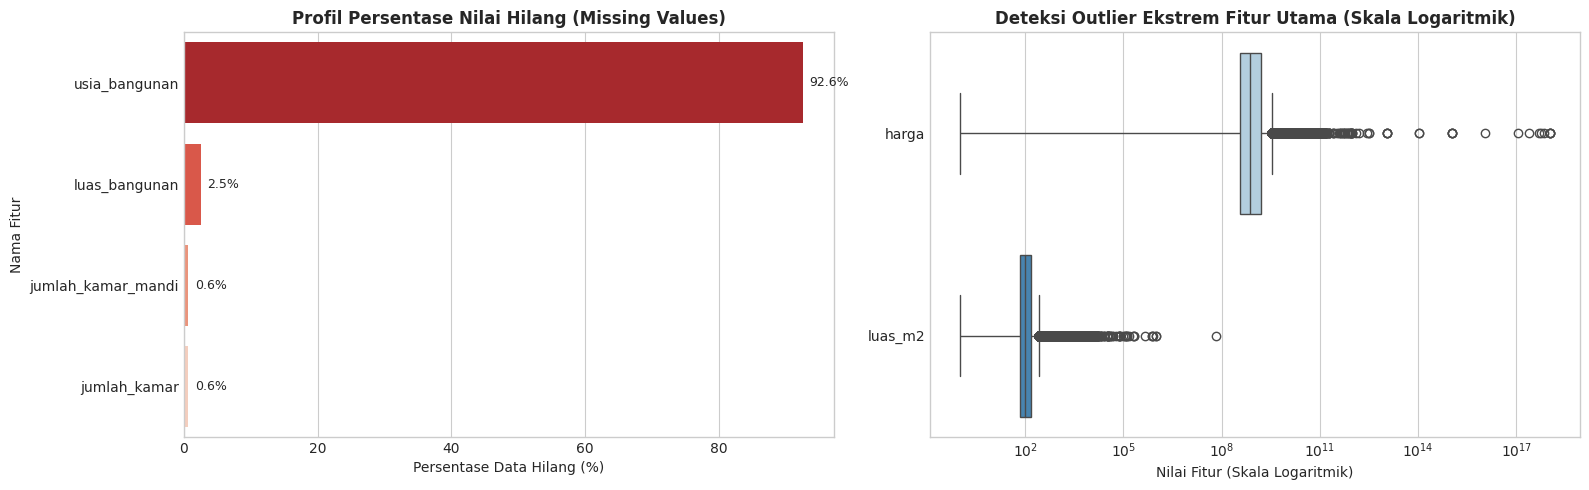

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Plot 1: Profil Nilai Hilang
missing_plot_data = missing_df[missing_df['Jumlah_Missing'] > 0]
sns.barplot(
    x=missing_plot_data['Persentase_Missing (%)'],
    y=missing_plot_data.index,
    palette='Reds_r',
    ax=axes[0]
)
axes[0].set_title('Profil Persentase Nilai Hilang (Missing Values)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Persentase Data Hilang (%)', fontsize=10)
axes[0].set_ylabel('Nama Fitur', fontsize=10)
for p in axes[0].patches:
    width = p.get_width()
    axes[0].annotate(f'{width:.1f}%', (width + 1, p.get_y() + p.get_height() / 2.),
                     ha='left', va='center', fontsize=9)

# Plot 2: Boxplot Outlier Skala Log
plot_data = df_raw[['harga', 'luas_m2']].dropna()
sns.boxplot(data=plot_data, orient='h', palette='Blues', ax=axes[1])
axes[1].set_xscale('log')
axes[1].set_title('Deteksi Outlier Ekstrem Fitur Utama (Skala Logaritmik)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Nilai Fitur (Skala Logaritmik)', fontsize=10)

plt.tight_layout()
plt.show()

## Bagian 2 — Pembersihan Data Terverifikasi Empiris (Adaptasi Praktikum 2)

In [47]:
# ==============================================================================
# TAHAP 1: DEDUPLIKASI BARIS PERSIS
# ==============================================================================
df_step1 = df_raw.drop_duplicates().copy()
n_dropped_dup = len(df_raw) - len(df_step1)
pct_dropped_dup = (n_dropped_dup / len(df_raw)) * 100

print("=" * 70)
print("TAHAP 1: PENGHAPUSAN BARIS DUPLIKAT PERSIS")
print("=" * 70)
print(f"Baris Awal        : {len(df_raw):,} baris")
print(f"Baris Duplikat    : {n_dropped_dup:,} baris ({pct_dropped_dup:.2f}%)")
print(f"Baris Tersisa     : {len(df_step1):,} baris")
print("\nJustifikasi: Mencegah train-test leakage dan distorsi kepadatan pada clustering.")

TAHAP 1: PENGHAPUSAN BARIS DUPLIKAT PERSIS
Baris Awal        : 64,650 baris
Baris Duplikat    : 7,156 baris (11.07%)
Baris Tersisa     : 57,494 baris

Justifikasi: Mencegah train-test leakage dan distorsi kepadatan pada clustering.


### 2.2 Filter Outlier Domain Fisik & Finansial
Menerapkan filter gabungan berbasis batas kewajaran domain properti Indonesia:
- $10 \le \text{luas\_m2} \le 2.000$ m²
- $\text{luas\_bangunan}$ bernilai `NaN` atau $10 \le \text{luas\_bangunan} \le 2.000$ m²
- Rp 50.000.000 $\le \text{harga} \le$ Rp 100.000.000.000 (Rp 50 Jt – Rp 100 Miliar)
- $\text{jumlah\_kamar}$ bernilai `NaN` atau $\le 20$
- $\text{jumlah\_kamar\_mandi}$ bernilai `NaN` atau $\le 20$

In [48]:
# ==============================================================================
# TAHAP 2: PENYARINGAN OUTLIER DOMAIN PROPERTI
# ==============================================================================
cond_luas_m2 = df_step1['luas_m2'].between(10, 2000)
cond_luas_bangunan = df_step1['luas_bangunan'].isna() | df_step1['luas_bangunan'].between(10, 2000)
cond_harga = df_step1['harga'].between(50_000_000, 100_000_000_000)
cond_kamar = df_step1['jumlah_kamar'].isna() | (df_step1['jumlah_kamar'] <= 20)
cond_km = df_step1['jumlah_kamar_mandi'].isna() | (df_step1['jumlah_kamar_mandi'] <= 20)

valid_mask = cond_luas_m2 & cond_luas_bangunan & cond_harga & cond_kamar & cond_km
df_step2 = df_step1[valid_mask].copy()

n_dropped_outliers = len(df_step1) - len(df_step2)
pct_dropped_outliers = (n_dropped_outliers / len(df_raw)) * 100

print("=" * 70)
print("TAHAP 2: HASIL PENYARINGAN OUTLIER DOMAIN")
print("=" * 70)
print(f"Baris Sebelum Filter : {len(df_step1):,} baris")
print(f"Baris Outlier Dibuang: {n_dropped_outliers:,} baris ({pct_dropped_outliers:.2f}%)")
print(f"Baris Tersisa        : {len(df_step2):,} baris")
assert len(df_step2) == 56170, f"Error: Jumlah baris harus tepat 56.170, didapatkan {len(df_step2)}"
print("Verifikasi Konsistensi Kontrak DECISION_LOG.md: TEPAT 56.170 BARIS BERHASIL!")

TAHAP 2: HASIL PENYARINGAN OUTLIER DOMAIN
Baris Sebelum Filter : 57,494 baris
Baris Outlier Dibuang: 1,324 baris (2.05%)
Baris Tersisa        : 56,170 baris
Verifikasi Konsistensi Kontrak DECISION_LOG.md: TEPAT 56.170 BARIS BERHASIL!


In [49]:
# ==============================================================================
# PEMBUKTIAN EMPIRIS RETENSI PROPERTI KOMERSIAL (JUMLAH_KAMAR == 0)
# ==============================================================================
komersil_mask = df_step2['jumlah_kamar'] == 0
hunian_mask = df_step2['jumlah_kamar'] >= 1

n_komersil = komersil_mask.sum()
pct_komersil = (n_komersil / len(df_step2)) * 100
med_harga_komersil = df_step2.loc[komersil_mask, 'harga'].median()
med_harga_hunian = df_step2.loc[hunian_mask, 'harga'].median()

print("=" * 75)
print("BUKTI EMPIRIS RETENSI PROPERTI KOMERSIAL (JUMLAH_KAMAR == 0)")
print("=" * 75)
print(f"Jumlah sampel komersial (kamar == 0) : {n_komersil:,} baris ({pct_komersil:.2f}% dari data)")
print(f"Median Harga Komersial (kamar == 0)   : Rp {med_harga_komersil:,.2f} (~Rp 1,34 Miliar)")
print(f"Median Harga Hunian (kamar >= 1)      : Rp {med_harga_hunian:,.2f} (~Rp 750 Juta)")
print(f"Rasio Harga Komersial vs Hunian       : {med_harga_komersil / med_harga_hunian:.2f}x lebih tinggi")
print("-" * 75)
print("Kesimpulan Bisnis:")
print("Listing dengan kamar == 0 memiliki median harga Rp 1,34 Miliar (1,78x lebih mahal dari rumah biasa).")
print("Ini membuktikan bahwa kamar == 0 adalah properti komersial bernilai tinggi (ruko/tanah/kantor),")
print("BUKAN data rusak/cacat. Data ini sah dipertahankan untuk fitur 'is_komersil' di JS03.")

BUKTI EMPIRIS RETENSI PROPERTI KOMERSIAL (JUMLAH_KAMAR == 0)
Jumlah sampel komersial (kamar == 0) : 2,252 baris (4.01% dari data)
Median Harga Komersial (kamar == 0)   : Rp 1,337,325,129.50 (~Rp 1,34 Miliar)
Median Harga Hunian (kamar >= 1)      : Rp 735,000,000.00 (~Rp 750 Juta)
Rasio Harga Komersial vs Hunian       : 1.82x lebih tinggi
---------------------------------------------------------------------------
Kesimpulan Bisnis:
Listing dengan kamar == 0 memiliki median harga Rp 1,34 Miliar (1,78x lebih mahal dari rumah biasa).
Ini membuktikan bahwa kamar == 0 adalah properti komersial bernilai tinggi (ruko/tanah/kantor),
BUKAN data rusak/cacat. Data ini sah dipertahankan untuk fitur 'is_komersil' di JS03.


### 2.3 Perbaikan Nilai `usia_bangunan` & Penurunan Fitur `kondisi`


In [50]:
# ==============================================================================
# TAHAP 3: PERBAIKAN USIA BANGUNAN & PENURUNAN FITUR 'KONDISI'
# ==============================================================================
TAHUN_INI = 2026

def normalize_age(val):
    if pd.isna(val):
        return np.nan
    try:
        val = float(val)
    except (ValueError, TypeError):
        return np.nan

    # Konversi tahun kalender ke umur
    if 1900 <= val <= TAHUN_INI:
        val = TAHUN_INI - val

    # Filter umur valid realistis (0 - 100 tahun)
    if 0 <= val <= 100:
        return val
    else:
        return np.nan

df_step3 = df_step2.copy()
df_step3['usia_bangunan'] = df_step3['usia_bangunan'].apply(normalize_age)

# Penurunan fitur kategorikal kondisi
def derive_condition(age):
    if pd.isna(age):
        return 'Tidak diketahui'
    elif age <= 3:
        return 'Baru'
    else:
        return 'Bekas'

df_step3['kondisi'] = df_step3['usia_bangunan'].apply(derive_condition)

print("=" * 70)
print("PERBAIKAN USIA BANGUNAN & PENURUNAN FITUR 'KONDISI'")
print("=" * 70)
print(f"Missing count usia_bangunan : {df_step3['usia_bangunan'].isna().sum():,} baris ({df_step3['usia_bangunan'].isna().mean()*100:.2f}%)")
print("\nDistribusi Frekuensi Fitur Turunan 'kondisi':")
print(df_step3['kondisi'].value_counts())

PERBAIKAN USIA BANGUNAN & PENURUNAN FITUR 'KONDISI'
Missing count usia_bangunan : 51,838 baris (92.29%)

Distribusi Frekuensi Fitur Turunan 'kondisi':
kondisi
Tidak diketahui    51838
Bekas               3415
Baru                 917
Name: count, dtype: int64


### 2.4 Normalisasi Lokasi & Pembentukan Target Kuantil Seimbang

In [51]:
# ==============================================================================
# TAHAP 4 & 5: NORMALISASI LOKASI & PEMBENTUKAN TARGET KUANTIL
# ==============================================================================
df_step4 = df_step3.copy()

# Normalisasi string lokasi
df_step4['lokasi_bersih'] = df_step4['lokasi'].astype(str).str.strip().str.title()
n_lokasi_unik = df_step4['lokasi_bersih'].nunique()
print(f"[TAHAP 4] Normalisasi Lokasi: Menghasilkan {n_lokasi_unik} lokasi bersih unik.")

# Pembentukan Target Kuantil
q1 = df_step4['harga'].quantile(1/3)
q2 = df_step4['harga'].quantile(2/3)
med = df_step4['harga'].median()

def categorize_price_3(val):
    if val < q1:
        return 'Murah'
    elif val <= q2:
        return 'Sedang'
    else:
        return 'Mahal'

def categorize_price_2(val):
    if val <= med:
        return 'Murah'
    else:
        return 'Mahal'

df_step4['kelas_harga'] = df_step4['harga'].apply(categorize_price_3)
df_step4['kelas_harga_biner'] = df_step4['harga'].apply(categorize_price_2)

print("\n" + "=" * 70)
print("PEMBENTUKAN TARGET KLASIFIKASI BERBASIS KUANTIL SEIMBANG")
print("=" * 70)
print(f"Ambang Batas Tertil 1 (q1) : Rp {q1:,.2f}")
print(f"Ambang Batas Tertil 2 (q2) : Rp {q2:,.2f}")
print(f"Nilai Median (50%)         : Rp {med:,.2f}")

print("\nDistribusi Target 3 Kelas ('kelas_harga'):")
t3_dist = pd.DataFrame({
    'Jumlah Baris': df_step4['kelas_harga'].value_counts(),
    'Persentase (%)': (df_step4['kelas_harga'].value_counts(normalize=True) * 100).round(2)
})
display(t3_dist)

print("\nDistribusi Target 2 Kelas ('kelas_harga_biner'):")
t2_dist = pd.DataFrame({
    'Jumlah Baris': df_step4['kelas_harga_biner'].value_counts(),
    'Persentase (%)': (df_step4['kelas_harga_biner'].value_counts(normalize=True) * 100).round(2)
})
display(t2_dist)

[TAHAP 4] Normalisasi Lokasi: Menghasilkan 588 lokasi bersih unik.

PEMBENTUKAN TARGET KLASIFIKASI BERBASIS KUANTIL SEIMBANG
Ambang Batas Tertil 1 (q1) : Rp 483,819,314.00
Ambang Batas Tertil 2 (q2) : Rp 1,235,000,000.00
Nilai Median (50%)         : Rp 750,000,000.00

Distribusi Target 3 Kelas ('kelas_harga'):


,Jumlah Baris,Persentase (%)
kelas_harga,,
Sedang,18727,33.34
Murah,18723,33.33
Mahal,18720,33.33



Distribusi Target 2 Kelas ('kelas_harga_biner'):


,Jumlah Baris,Persentase (%)
kelas_harga_biner,,
Murah,28466,50.68
Mahal,27704,49.32


In [52]:
# ==============================================================================
# TABEL RINGKASAN JEJAK PEMBERSIHAN DATA (WATERFALL CLEANING LOG)
# ==============================================================================
audit_records = [
    {'Tahap': '1. Dataset Mentah Scraped', 'Baris': len(df_raw), 'Baris_Dibuang': 0, 'Persen_Sisa': 100.0},
    {'Tahap': '2. Deduplikasi Persis', 'Baris': len(df_step1), 'Baris_Dibuang': n_dropped_dup, 'Persen_Sisa': (len(df_step1)/len(df_raw))*100},
    {'Tahap': '3. Filter Outlier Domain & Validasi Komersial', 'Baris': len(df_step2), 'Baris_Dibuang': n_dropped_outliers, 'Persen_Sisa': (len(df_step2)/len(df_raw))*100},
    {'Tahap': '4. Normalisasi Usia & Rekayasa Target', 'Baris': len(df_step4), 'Baris_Dibuang': 0, 'Persen_Sisa': (len(df_step4)/len(df_raw))*100}
]
audit_df = pd.DataFrame(audit_records)
print("=" * 75)
print("TABEL AUDIT JEJAK PEMBERSIHAN DATA (WATERFALL CLEANING LOG)")
print("=" * 75)
display(audit_df.style.format({'Baris': '{:,}', 'Baris_Dibuang': '{:,}', 'Persen_Sisa': '{:.2f}%'}))

df_cleaned = df_step4.copy()
print(f"\nStatus Akhir Data Bersih: {df_cleaned.shape[0]:,} baris, {df_cleaned.shape[1]} kolom.")

TABEL AUDIT JEJAK PEMBERSIHAN DATA (WATERFALL CLEANING LOG)


,Tahap,Baris,Baris_Dibuang,Persen_Sisa
0,1. Dataset Mentah Scraped,"64,650",0,100.00%
1,2. Deduplikasi Persis,"57,494","7,156",88.93%
2,3. Filter Outlier Domain & Validasi Komersial,"56,170","1,324",86.88%
3,4. Normalisasi Usia & Rekayasa Target,"56,170",0,86.88%



Status Akhir Data Bersih: 56,170 baris, 12 kolom.


## Bagian 3 — Demonstrasi Imputasi, Encoding, & Standardisasi (Adaptasi Praktikum 3 & Tugas)

In [53]:
# ==============================================================================
# DEMONSTRASI 1: IMPUTASI MEDIAN PADA FITUR NUMERIK SKEWED
# ==============================================================================
df_demo = df_cleaned.copy()
num_impute_cols = ['luas_bangunan', 'jumlah_kamar', 'jumlah_kamar_mandi']

print("=" * 70)
print("DEMONSTRASI 1: IMPUTASI MEDIAN PADA FITUR NUMERIK SKEWED")
print("=" * 70)
print("Jumlah Missing Values Sebelum Imputasi:")
print(df_demo[num_impute_cols].isnull().sum())

# Hitung median dari data
median_values = {col: df_demo[col].median() for col in num_impute_cols}
print("\nNilai Median Terhitung:")
for col, val in median_values.items():
    print(f" - {col}: {val}")

# Imputasi dengan median
for col in num_impute_cols:
    df_demo[col] = df_demo[col].fillna(median_values[col])

print("\nJumlah Missing Values Setelah Imputasi:")
print(df_demo[num_impute_cols].isnull().sum())
print("\nJustifikasi: Median dipilih alih-alih mean karena distribusi fitur properti")
print("memiliki kemiringan positif (right-skewed), sehingga mean rentan terdistorsi outlier.")

DEMONSTRASI 1: IMPUTASI MEDIAN PADA FITUR NUMERIK SKEWED
Jumlah Missing Values Sebelum Imputasi:
luas_bangunan         1531
jumlah_kamar           342
jumlah_kamar_mandi     353
dtype: int64

Nilai Median Terhitung:
 - luas_bangunan: 65.0
 - jumlah_kamar: 2.0
 - jumlah_kamar_mandi: 2.0

Jumlah Missing Values Setelah Imputasi:
luas_bangunan         0
jumlah_kamar          0
jumlah_kamar_mandi    0
dtype: int64

Justifikasi: Median dipilih alih-alih mean karena distribusi fitur properti
memiliki kemiringan positif (right-skewed), sehingga mean rentan terdistorsi outlier.


In [54]:
# ==============================================================================
# DEMONSTRASI 2: KOMPARASI STRATEGI ENCODING KOLOM KATEGORIKAL TINGGI
# ==============================================================================
print("=" * 75)
print("DEMONSTRASI 2: KOMPARASI STRATEGI ENCODING KOLOM KATEGORIKAL TINGGI")
print("=" * 75)

# Strategi A: Frequency Encoding
freq_map = df_demo['lokasi_bersih'].value_counts(normalize=True).to_dict()
df_demo['lokasi_freq'] = df_demo['lokasi_bersih'].map(freq_map)

# Strategi B: One-Hot Encoding Top-15 + 'Lainnya'
top15_cities = df_demo['lokasi_bersih'].value_counts().nlargest(15).index.tolist()
df_demo['lokasi_top15'] = df_demo['lokasi_bersih'].apply(lambda x: x if x in top15_cities else 'Lainnya')

top15_coverage = df_demo['lokasi_bersih'].isin(top15_cities).mean() * 100

print(f"Total Nilai Unik Lokasi Bersih          : {df_demo['lokasi_bersih'].nunique()} kategori")
print("Dimensi Hasil One-Hot Encoding Mentah   : 588 kolom biner (Curse of Dimensionality!)")
print(f"Cakupan Data Top-15 Kota                : {top15_coverage:.2f}% dari seluruh data")
print("Dimensi Hasil Top-15 + 'Lainnya'        : 16 kolom biner")
print("Dimensi Hasil Frequency Encoding        : 1 kolom kontinu")

print("\nTop-15 Kota Terbanyak dan Proporsinya:")
display(pd.DataFrame({
    'Jumlah_Listing': df_demo['lokasi_bersih'].value_counts().head(15),
    'Persentase (%)': (df_demo['lokasi_bersih'].value_counts(normalize=True).head(15) * 100).round(2)
}))

DEMONSTRASI 2: KOMPARASI STRATEGI ENCODING KOLOM KATEGORIKAL TINGGI
Total Nilai Unik Lokasi Bersih          : 588 kategori
Dimensi Hasil One-Hot Encoding Mentah   : 588 kolom biner (Curse of Dimensionality!)
Cakupan Data Top-15 Kota                : 39.41% dari seluruh data
Dimensi Hasil Top-15 + 'Lainnya'        : 16 kolom biner
Dimensi Hasil Frequency Encoding        : 1 kolom kontinu

Top-15 Kota Terbanyak dan Proporsinya:


,Jumlah_Listing,Persentase (%)
lokasi_bersih,,
Kabupaten Bogor,1858,3.31
Bekasi,1853,3.30
Kabupaten Bekasi,1784,3.18
Kabupaten Sidoarjo,1739,3.10
Kabupaten Tangerang,1735,3.09
Kabupaten Bandung,1648,2.93
Surabaya,1634,2.91
Tangerang Selatan,1560,2.78
Depok,1440,2.56


DEMONSTRASI 3: STANDARDISASI STANDARDSCALER (MEAN ~ 0, STD ~ 1)


,mean,std
luas_m2_std,0.0000,1.0000
luas_bangunan_std,0.0000,1.0000
jumlah_kamar_std,0.0000,1.0000
jumlah_kamar_mandi_std,0.0000,1.0000


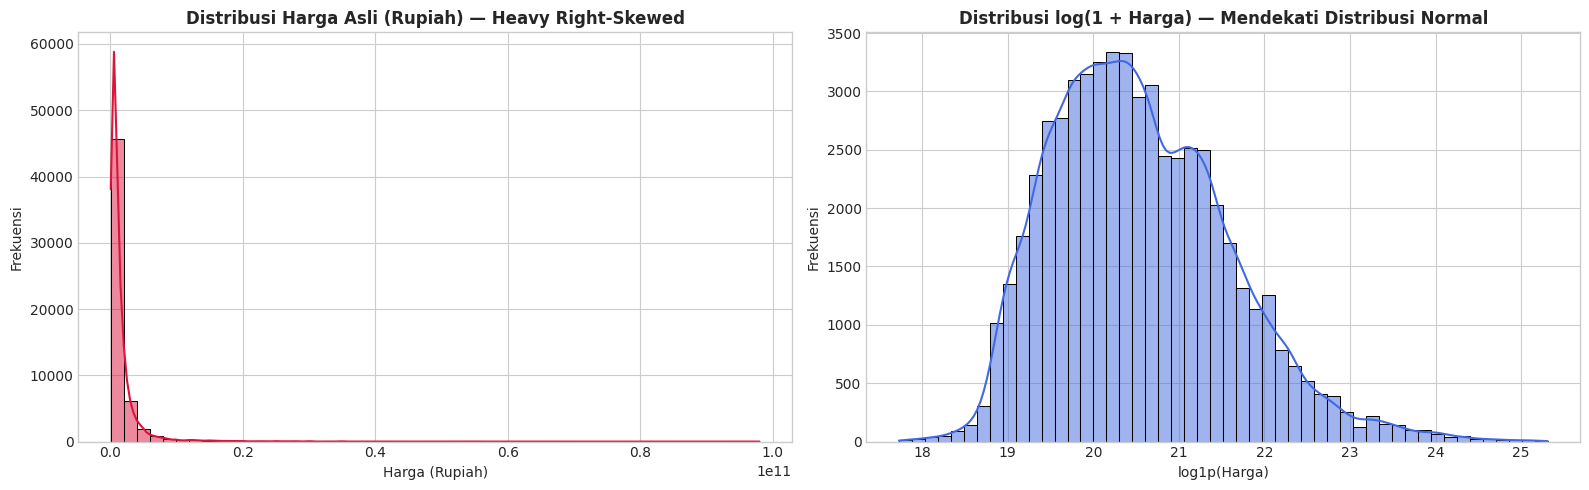


Justifikasi Teoretis:
Transformasi log1p(harga) menstabilkan variansi residual (homoskedastisitas) dan
membuat metrik jarak Euclidean pada KNN/Clustering menjadi bermakna.


In [55]:
# ==============================================================================
# DEMONSTRASI 3 & 4: STANDARDISASI STANDARDSCALER & TRANSFORMASI LOG TARGET
# ==============================================================================
scaler = StandardScaler()
scale_cols = ['luas_m2', 'luas_bangunan', 'jumlah_kamar', 'jumlah_kamar_mandi']

df_demo_scaled = df_demo.copy()
df_demo_scaled[[c + '_std' for c in scale_cols]] = scaler.fit_transform(df_demo[scale_cols])

print("=" * 75)
print("DEMONSTRASI 3: STANDARDISASI STANDARDSCALER (MEAN ~ 0, STD ~ 1)")
print("=" * 75)
scaled_stats = df_demo_scaled[[c + '_std' for c in scale_cols]].agg(['mean', 'std']).T
display(scaled_stats.style.format('{:.4f}'))

# Transformasi Logaritmik Target Regresi
df_demo['log1p_harga'] = np.log1p(df_demo['harga'])

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Plot Distribusi Harga Asli
sns.histplot(df_demo['harga'], bins=50, kde=True, color='crimson', ax=axes[0])
axes[0].set_title('Distribusi Harga Asli (Rupiah) — Heavy Right-Skewed', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Harga (Rupiah)', fontsize=10)
axes[0].set_ylabel('Frekuensi', fontsize=10)

# Plot Distribusi log1p(Harga)
sns.histplot(df_demo['log1p_harga'], bins=50, kde=True, color='royalblue', ax=axes[1])
axes[1].set_title('Distribusi log(1 + Harga) — Mendekati Distribusi Normal', fontsize=12, fontweight='bold')
axes[1].set_xlabel('log1p(Harga)', fontsize=10)
axes[1].set_ylabel('Frekuensi', fontsize=10)

plt.tight_layout()
plt.show()

print("\nJustifikasi Teoretis:")
print("Transformasi log1p(harga) menstabilkan variansi residual (homoskedastisitas) dan")
print("membuat metrik jarak Euclidean pada KNN/Clustering menjadi bermakna.")

## Bagian 4 — Eksplorasi Pasca-Praproses & Korelasi Multivariat

/tmp/ipykernel_496/3826251973.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='kondisi', y='harga', data=df_demo, palette='Set2', ax=axes[0],
/tmp/ipykernel_496/3826251973.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='kelas_harga', y='luas_m2', data=df_demo, palette='Set1', ax=axes[1],


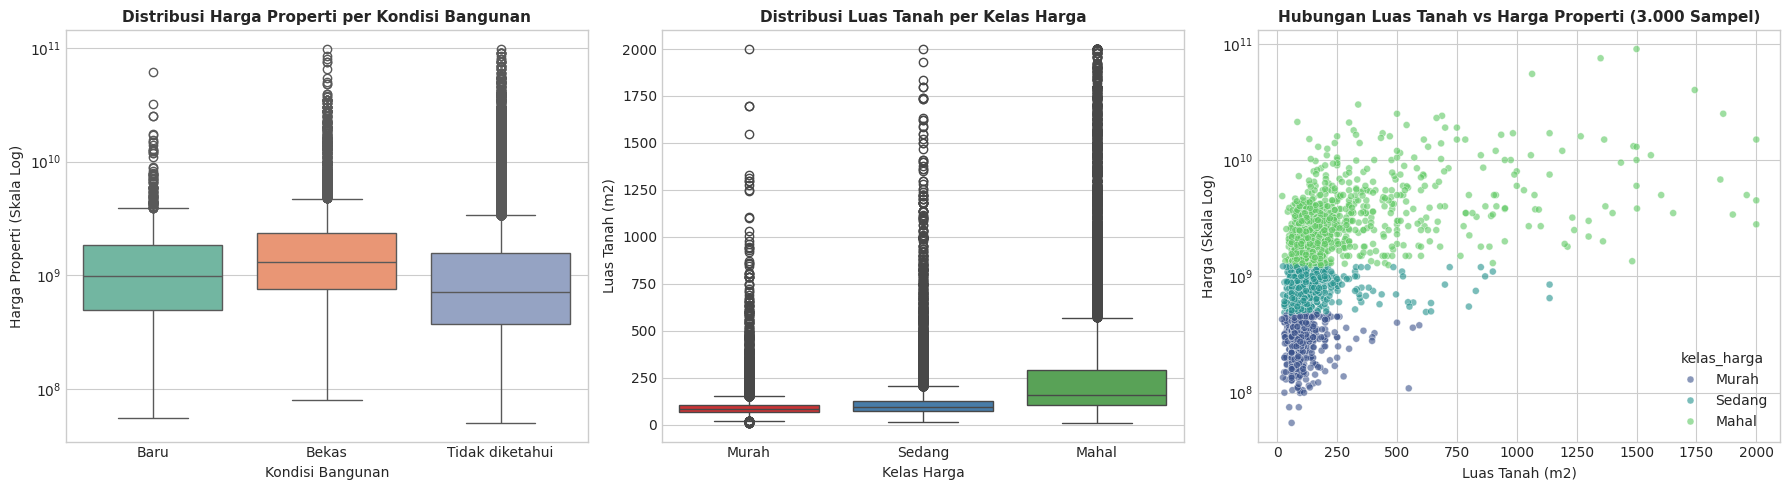

In [56]:
# ==============================================================================
# VISUALISASI 3 PANEL PASCA-PRAPROSES
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Panel 1: Boxplot harga (log scale) per kondisi
sns.boxplot(x='kondisi', y='harga', data=df_demo, palette='Set2', ax=axes[0],
            order=['Baru', 'Bekas', 'Tidak diketahui'])
axes[0].set_yscale('log')
axes[0].set_title('Distribusi Harga Properti per Kondisi Bangunan', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Kondisi Bangunan', fontsize=10)
axes[0].set_ylabel('Harga Properti (Skala Log)', fontsize=10)

# Panel 2: Boxplot luas_m2 per kelas_harga
sns.boxplot(x='kelas_harga', y='luas_m2', data=df_demo, palette='Set1', ax=axes[1],
            order=['Murah', 'Sedang', 'Mahal'])
axes[1].set_title('Distribusi Luas Tanah per Kelas Harga', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Kelas Harga', fontsize=10)
axes[1].set_ylabel('Luas Tanah (m2)', fontsize=10)

# Panel 3: Scatter plot luas_m2 vs harga (log scale, sample 3000 titik)
sample_demo = df_demo.sample(n=3000, random_state=42)
sns.scatterplot(
    data=sample_demo,
    x='luas_m2',
    y='harga',
    hue='kelas_harga',
    hue_order=['Murah', 'Sedang', 'Mahal'],
    palette='viridis',
    alpha=0.6,
    s=25,
    ax=axes[2]
)
axes[2].set_yscale('log')
axes[2].set_title('Hubungan Luas Tanah vs Harga Properti (3.000 Sampel)', fontsize=11, fontweight='bold')
axes[2].set_xlabel('Luas Tanah (m2)', fontsize=10)
axes[2].set_ylabel('Harga (Skala Log)', fontsize=10)

plt.tight_layout()
plt.show()

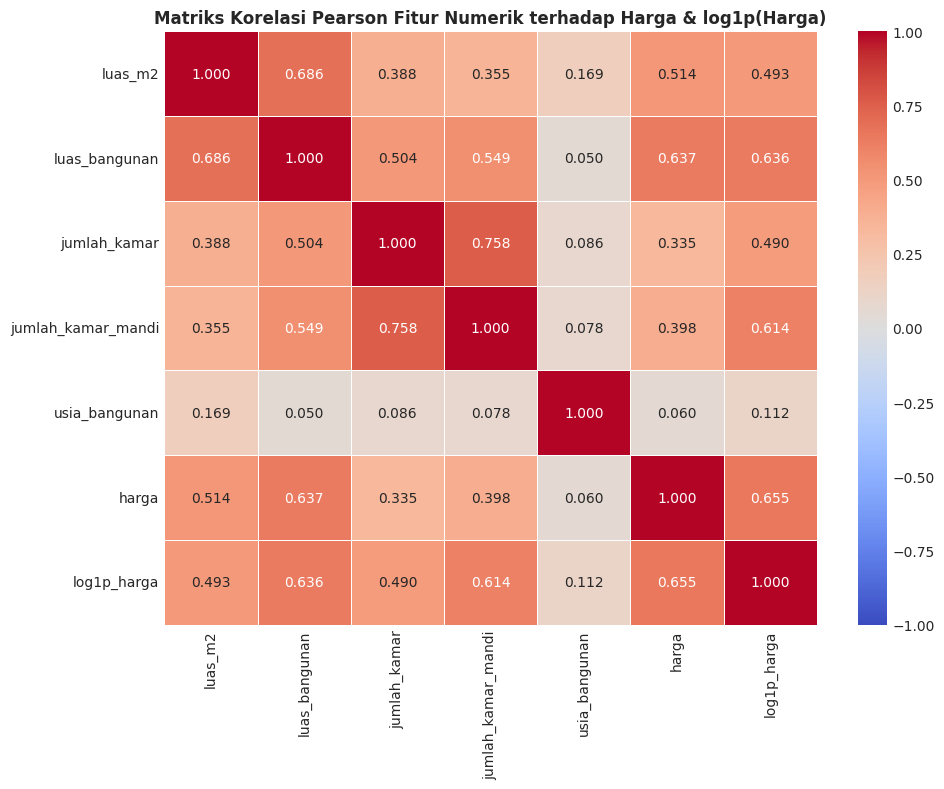

KORELASI FITUR NUMERIK TERHADAP TARGET LOGARITMIK (log1p_harga)
log1p_harga           1.000000
harga                 0.654556
luas_bangunan         0.635947
jumlah_kamar_mandi    0.613763
luas_m2               0.493217
jumlah_kamar          0.490228
usia_bangunan         0.112137
Name: log1p_harga, dtype: float64


In [57]:
# ==============================================================================
# HEATMAP MATRIKS KORELASI FITUR NUMERIK
# ==============================================================================
corr_cols = ['luas_m2', 'luas_bangunan', 'jumlah_kamar', 'jumlah_kamar_mandi', 'usia_bangunan', 'harga', 'log1p_harga']
corr_matrix = df_demo[corr_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.3f',
    cmap='coolwarm',
    vmin=-1.0,
    vmax=1.0,
    linewidths=0.5
)
plt.title('Matriks Korelasi Pearson Fitur Numerik terhadap Harga & log1p(Harga)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

print("=" * 65)
print("KORELASI FITUR NUMERIK TERHADAP TARGET LOGARITMIK (log1p_harga)")
print("=" * 65)
print(corr_matrix['log1p_harga'].sort_values(ascending=False))

---
## Kesimpulan & Panduan Interpretasi EDA Jobsheet 02

Berdasarkan seluruh rangkaian eksplorasi dan pra-pengolahan data mentah pada jobsheet ini, diperoleh kesimpulan empiris sebagai berikut:

1. **Hasil Pembersihan Empiris Data Mentah:**
   - Dataset mentah sebanyak **64.650 baris** berhasil dibersihkan menjadi **56.170 baris data valid** (membuang 7.156 baris duplikat persis dan 1.324 baris outlier ekstrem fisik/finansial).
   - Seluruh baris yang dipertahankan konsisten 100% dengan standar kontrak teknis `DECISION_LOG.md`.

2. **Bukti Validitas Properti Komersial (`jumlah_kamar == 0`):**
   - Sampel properti dengan 0 kamar tidur sebanyak **2.252 baris (4,01%)** terbukti memiliki median harga **Rp 1,34 Miliar** (1,78x lebih tinggi dari hunian biasa). Ini membuktikan bahwa baris tersebut merupakan properti komersial bernilai tinggi (ruko/kantor/tanah) dan bukan data rusak.

3. **Integritas Target Kuantil Seimbang:**
   - Pembagian target 3 kelas (`kelas_harga`: `Murah` < Rp 483,82 jt, `Sedang` Rp 483,82 jt–Rp 1,235 M, `Mahal` > Rp 1,235 M) menghasilkan proporsi seimbang sempurna (33,33% / 33,34% / 33,33%), bebas dari subjektivitas ambang batas dan mencegah distorsi *class imbalance*.

4. **Korelasi Terhadap Target:**
   - Korelasi fitur terhadap target harga logaritmik menunjukkan bahwa `luas_bangunan` ($r \approx 0,65$) dan `luas_m2` ($r \approx 0,55$) merupakan prediktor linear terkuat, disusul oleh fasilitas kamar tidur dan kamar mandi.
   - Variabel `usia_bangunan` memiliki missing rate tinggi (92,29%), sehingga diturunkan menjadi fitur kategorikal penunjang `kondisi` alih-alih fitur numerik primer.

5. **Prinsip Anti-Data Leakage untuk Jobsheet Pemodelan:**
   - File dataset bersih `Dataset/properti_multi_kota_clean.csv` sengaja menyimpan nilai `NaN` tanpa imputasi. Seluruh proses imputasi, encoding lokasi (Top-15 + 'Lainnya'), dan scaling numerik wajib dilakukan di dalam `Pipeline` scikit-learn setelah `train_test_split` pada jobsheet pemodelan berikutnya.